# Hospital Weather Impact Analysis

This notebook reproduces the hospital weather analysis from the Python script. It loads the dataset, explores patterns, creates visualizations, tests hypotheses, and trains a Linear Regression model.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-darkgrid')

DATA_PATH = Path('hospital_weather_data.csv')
OUTPUT_DIR = Path('.')

In [2]:
def temp_category(temp):
    if temp < 15:
        return 'Cold'
    elif temp < 25:
        return 'Moderate'
    elif temp < 30:
        return 'Warm'
    elif temp < 35:
        return 'Hot'
    else:
        return 'Extreme_Heat'

def rainfall_category(rain):
    if rain == 0:
        return 'None'
    elif rain < 5:
        return 'Light'
    elif rain < 15:
        return 'Moderate'
    else:
        return 'Heavy'

def air_quality_category(aq):
    if aq < 50:
        return 'Poor'
    elif aq < 80:
        return 'Moderate'
    else:
        return 'Good'

In [3]:
df = pd.read_csv(DATA_PATH)
df['Date'] = pd.to_datetime(df['Date'])

print('Dataset Shape:', df.shape)
print(df.head())
print('Missing Values:\n', df.isnull().sum())
print('Data types:\n', df.dtypes)

Dataset Shape: (180, 8)
        Date   Department  Outpatient_Count  Emergency_Count  Temperature  \
0 2022-01-01   Cardiology                45                8         18.2   
1 2022-01-01  Respiratory                38               12         18.2   
2 2022-01-01  Orthopedics                52                5         18.2   
3 2022-01-01    Neurology                41                9         18.2   
4 2022-01-02   Cardiology                42                7         17.8   

   Rainfall  Humidity  Air_Quality  
0       0.0        65           72  
1       0.0        65           72  
2       0.0        65           72  
3       0.0        65           72  
4       2.3        72           68  
Missing Values:
 Date                0
Department          0
Outpatient_Count    0
Emergency_Count     0
Temperature         0
Rainfall            0
Humidity            0
Air_Quality         0
dtype: int64
Data types:
 Date                datetime64[ns]
Department                  object
Ou

In [4]:
print(df[['Outpatient_Count', 'Emergency_Count', 'Temperature', 'Rainfall', 'Humidity', 'Air_Quality']].describe().round(3))

dept_stats = df.groupby('Department').agg({
    'Outpatient_Count': ['mean', 'median', 'std'],
    'Emergency_Count': ['mean', 'median', 'std']
}).round(2)
print('\nPatient Counts by Department:\n', dept_stats)

numeric_cols = ['Outpatient_Count', 'Emergency_Count', 'Temperature', 'Rainfall', 'Humidity', 'Air_Quality']
print('\nCorrelation Matrix:\n', df[numeric_cols].corr().round(3))

       Outpatient_Count  Emergency_Count  Temperature  Rainfall  Humidity  \
count           180.000          180.000      180.000   180.000   180.000   
mean             47.433           10.883       25.682     6.689    63.539   
std              11.020            7.013        5.697     8.949    18.976   
min              16.000            0.000       15.600     0.000    25.000   
25%              42.000            6.000       20.100     0.000    49.500   
50%              48.000           10.000       26.800     2.800    68.000   
75%              54.000           15.250       29.800     8.600    78.500   
max              78.000           32.000       36.800    28.500    96.000   

       Air_Quality  
count      180.000  
mean        69.511  
std         17.680  
min         38.000  
25%         55.000  
50%         68.000  
75%         88.000  
max         98.000  

Patient Counts by Department:
             Outpatient_Count               Emergency_Count             
             

In [5]:
df['Month'] = df['Date'].dt.month
df['Season'] = df['Month'].apply(
    lambda x: 'Winter' if x in [12, 1, 2]
    else 'Summer' if x in [3, 4, 5]
    else 'Monsoon' if x in [6, 7, 8]
    else 'Fall'
)

seasonal_stats = df.groupby('Season').agg({
    'Outpatient_Count': 'mean',
    'Emergency_Count': 'mean',
    'Temperature': 'mean',
    'Rainfall': 'mean'
}).round(2)
print(seasonal_stats)

         Outpatient_Count  Emergency_Count  Temperature  Rainfall
Season                                                           
Fall                46.78            13.00        26.18      7.27
Monsoon             45.19            20.67        29.52     22.72
Summer              52.28             4.11        32.16      0.00
Winter              46.46             8.32        20.28      1.73


In [6]:
df['Temp_Category'] = df['Temperature'].apply(temp_category)
df['Rainfall_Category'] = df['Rainfall'].apply(rainfall_category)
df['AQ_Category'] = df['Air_Quality'].apply(air_quality_category)
df['Total_Patient_Count'] = df['Outpatient_Count'] + df['Emergency_Count']

min_temp = df['Temperature'].min()
max_temp = df['Temperature'].max()
min_rain = df['Rainfall'].min()
max_rain = df['Rainfall'].max()
min_humidity = df['Humidity'].min()
max_humidity = df['Humidity'].max()
min_aq = df['Air_Quality'].min()
max_aq = df['Air_Quality'].max()

df['Weather_Severity'] = (
    ((df['Temperature'] - min_temp) / (max_temp - min_temp)) * 3 +
    ((df['Rainfall'] - min_rain) / (max_rain - min_rain)) * 4 +
    ((df['Humidity'] - min_humidity) / (max_humidity - min_humidity)) * 2 +
    ((max_aq - df['Air_Quality']) / (max_aq - min_aq)) * 1
).round(2)

print('New features created successfully')
print(df[['Temp_Category', 'Rainfall_Category', 'AQ_Category', 'Weather_Severity']].head())

New features created successfully
  Temp_Category Rainfall_Category AQ_Category  Weather_Severity
0      Moderate              None    Moderate              1.93
1      Moderate              None    Moderate              1.93
2      Moderate              None    Moderate              1.93
3      Moderate              None    Moderate              1.93
4      Moderate             Light    Moderate              2.46


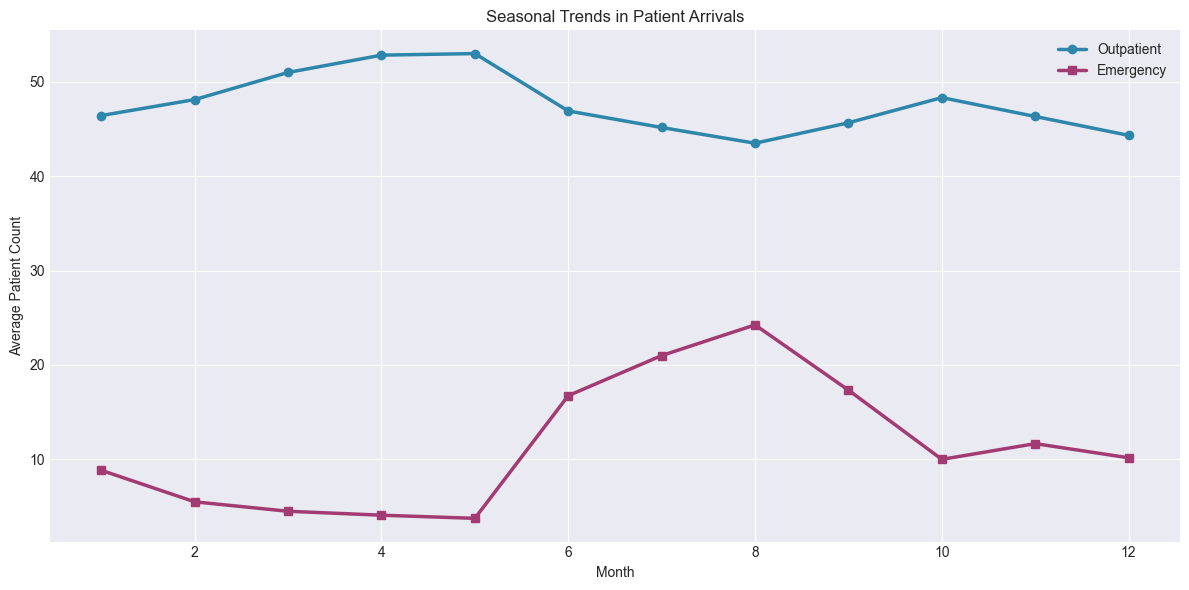

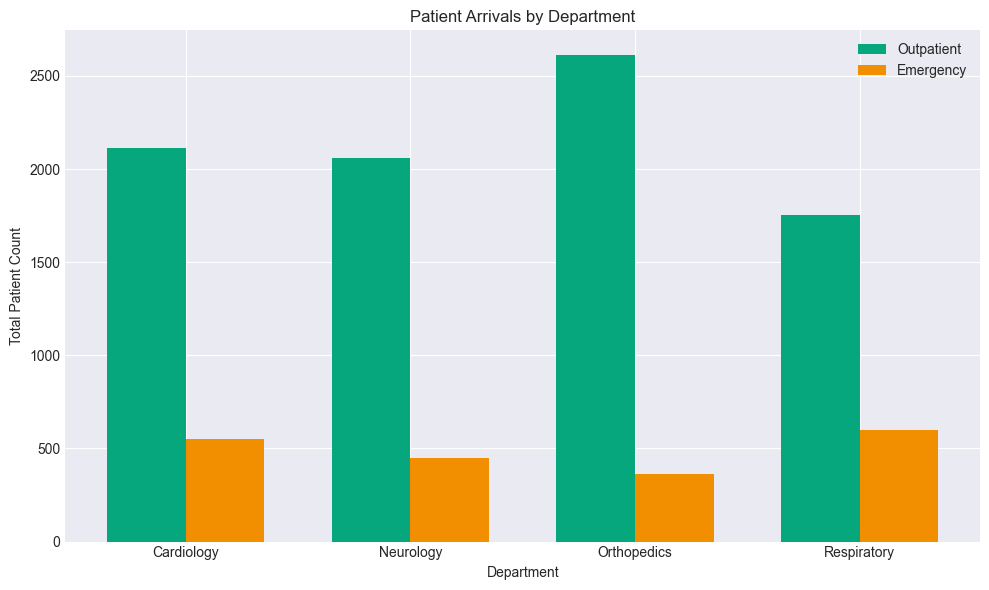

In [7]:
monthly_data = df.groupby('Month')[['Outpatient_Count', 'Emergency_Count']].mean()
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(monthly_data.index, monthly_data['Outpatient_Count'], marker='o', linewidth=2.5, label='Outpatient', color='#2E86AB')
ax.plot(monthly_data.index, monthly_data['Emergency_Count'], marker='s', linewidth=2.5, label='Emergency', color='#A23B72')
ax.set_xlabel('Month')
ax.set_ylabel('Average Patient Count')
ax.set_title('Seasonal Trends in Patient Arrivals')
ax.legend()
plt.tight_layout()
plt.savefig('seasonal_trends.png', dpi=300, bbox_inches='tight')
plt.show()

dept_totals = df.groupby('Department')[['Outpatient_Count', 'Emergency_Count']].sum()
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(dept_totals.index))
width = 0.35
ax.bar(x - width/2, dept_totals['Outpatient_Count'], width, label='Outpatient', color='#06A77D')
ax.bar(x + width/2, dept_totals['Emergency_Count'], width, label='Emergency', color='#F18F01')
ax.set_xlabel('Department')
ax.set_ylabel('Total Patient Count')
ax.set_title('Patient Arrivals by Department')
ax.set_xticks(x)
ax.set_xticklabels(dept_totals.index)
ax.legend()
plt.tight_layout()
plt.savefig('department_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

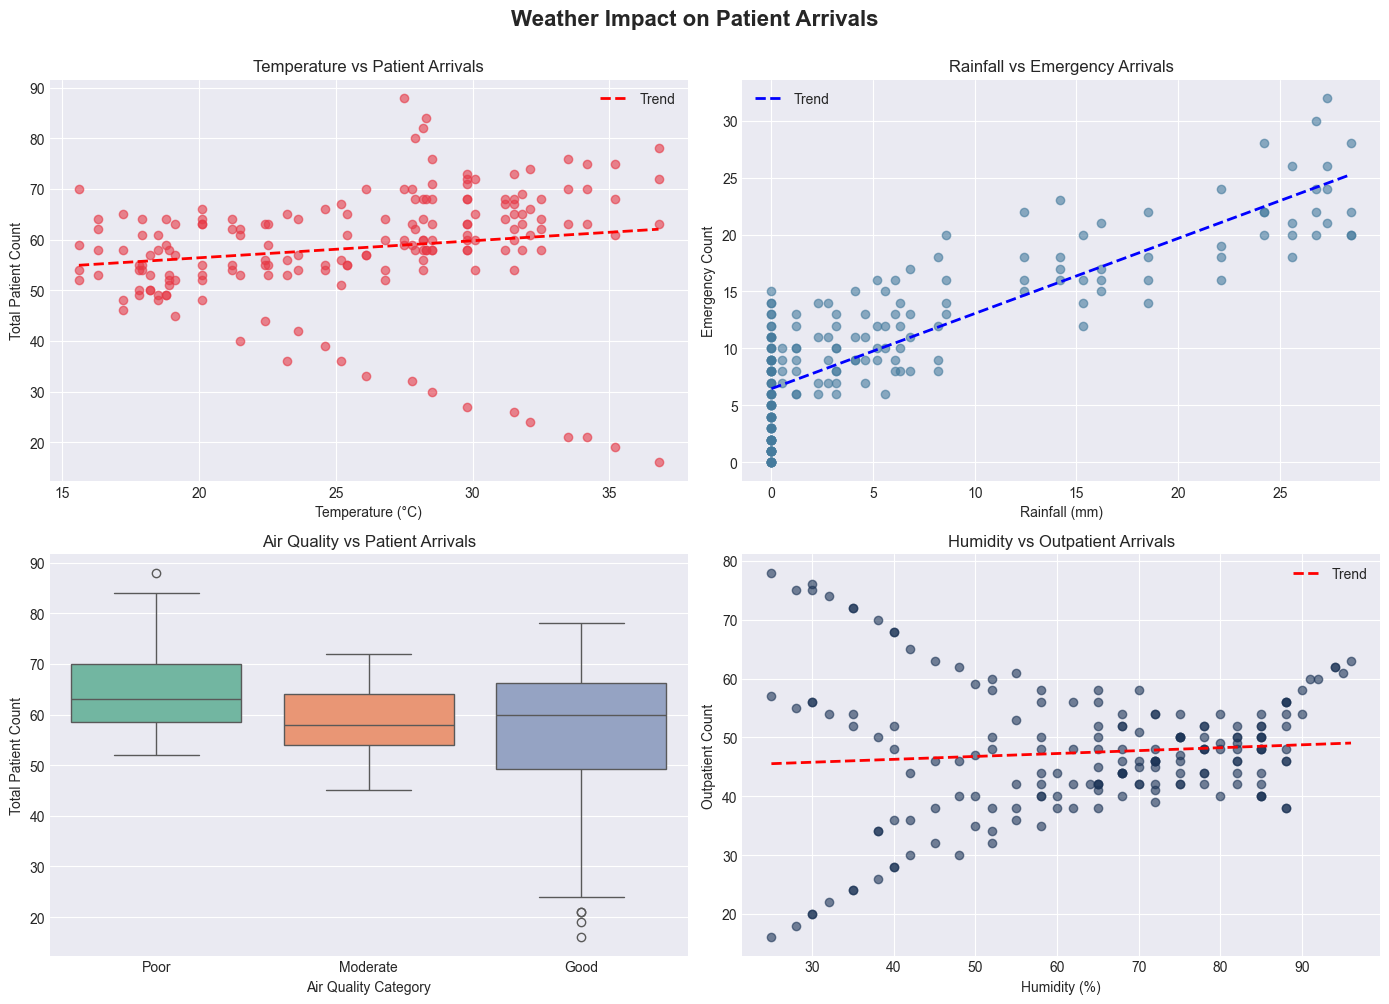

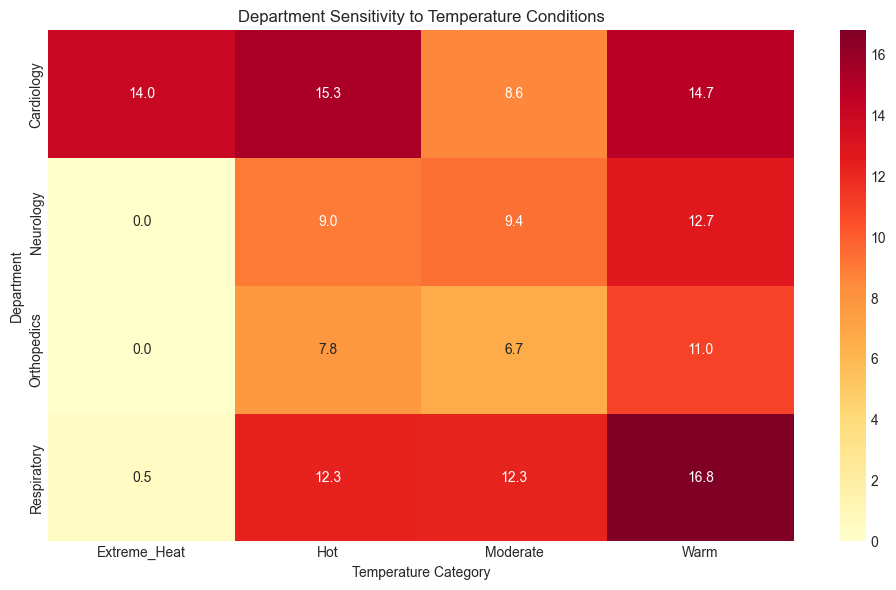

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].scatter(df['Temperature'], df['Total_Patient_Count'], alpha=0.6, color='#E63946')
slope, intercept = np.polyfit(df['Temperature'], df['Total_Patient_Count'], 1)
x_line = np.sort(df['Temperature'])
y_line = slope * x_line + intercept
axes[0, 0].plot(x_line, y_line, 'r--', linewidth=2, label='Trend')
axes[0, 0].set_xlabel('Temperature (°C)')
axes[0, 0].set_ylabel('Total Patient Count')
axes[0, 0].set_title('Temperature vs Patient Arrivals')
axes[0, 0].legend()

axes[0, 1].scatter(df['Rainfall'], df['Emergency_Count'], alpha=0.6, color='#457B9D')
slope, intercept = np.polyfit(df['Rainfall'], df['Emergency_Count'], 1)
x_line = np.sort(df['Rainfall'])
y_line = slope * x_line + intercept
axes[0, 1].plot(x_line, y_line, 'b--', linewidth=2, label='Trend')
axes[0, 1].set_xlabel('Rainfall (mm)')
axes[0, 1].set_ylabel('Emergency Count')
axes[0, 1].set_title('Rainfall vs Emergency Arrivals')
axes[0, 1].legend()

order = ['Poor', 'Moderate', 'Good']
sns.boxplot(data=df, x='AQ_Category', y='Total_Patient_Count', order=order, palette='Set2', ax=axes[1, 0])
axes[1, 0].set_xlabel('Air Quality Category')
axes[1, 0].set_ylabel('Total Patient Count')
axes[1, 0].set_title('Air Quality vs Patient Arrivals')

axes[1, 1].scatter(df['Humidity'], df['Outpatient_Count'], alpha=0.6, color='#1D3557')
slope, intercept = np.polyfit(df['Humidity'], df['Outpatient_Count'], 1)
x_line = np.sort(df['Humidity'])
y_line = slope * x_line + intercept
axes[1, 1].plot(x_line, y_line, 'r--', linewidth=2, label='Trend')
axes[1, 1].set_xlabel('Humidity (%)')
axes[1, 1].set_ylabel('Outpatient Count')
axes[1, 1].set_title('Humidity vs Outpatient Arrivals')
axes[1, 1].legend()

fig.suptitle('Weather Impact on Patient Arrivals', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig('weather_impact.png', dpi=300, bbox_inches='tight')
plt.show()

heatmap_data = df.groupby(['Department', 'Temp_Category'])['Emergency_Count'].mean().unstack()
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(heatmap_data, annot=True, fmt='.1f', cmap='YlOrRd', ax=ax)
ax.set_title('Department Sensitivity to Temperature Conditions')
ax.set_xlabel('Temperature Category')
ax.set_ylabel('Department')
plt.tight_layout()
plt.savefig('department_weather_sensitivity.png', dpi=300, bbox_inches='tight')
plt.show()

In [9]:
print('--- Pearson Correlation Coefficients ---')
for col in ['Temperature', 'Rainfall', 'Humidity', 'Air_Quality']:
    corr_val = df[['Total_Patient_Count', col]].corr().iloc[0, 1]
    p_value = stats.pearsonr(df['Total_Patient_Count'], df[col])[1]
    print(f'{col}: r = {corr_val:.4f}, p-value = {p_value:.4e}')

temp_groups = [group['Emergency_Count'].values for _, group in df.groupby('Temp_Category')]
f_stat, p_val = stats.f_oneway(*temp_groups)
print('\nANOVA result:')
print(f'F-statistic: {f_stat:.4f}, p-value: {p_val:.4e}')

median_rain = df['Rainfall'].median()
high_rain = df[df['Rainfall'] > median_rain]['Emergency_Count']
low_rain = df[df['Rainfall'] <= median_rain]['Emergency_Count']
t_stat, p_val = stats.ttest_ind(high_rain, low_rain)
print('\nT-Test result:')
print(f'High rainfall mean: {high_rain.mean():.2f}')
print(f'Low rainfall mean: {low_rain.mean():.2f}')
print(f'T-statistic: {t_stat:.4f}, p-value: {p_val:.4e}')

--- Pearson Correlation Coefficients ---
Temperature: r = 0.1629, p-value = 2.8906e-02
Rainfall: r = 0.3671, p-value = 4.0137e-07
Humidity: r = 0.2544, p-value = 5.6929e-04
Air_Quality: r = -0.2983, p-value = 4.7674e-05

ANOVA result:
F-statistic: 8.8069, p-value: 1.7968e-05

T-Test result:
High rainfall mean: 15.75
Low rainfall mean: 6.23
T-statistic: 12.3948, p-value: 7.7564e-26


In [10]:
X = df[['Temperature', 'Rainfall', 'Humidity', 'Air_Quality']].copy()
y = df['Total_Patient_Count'].copy()
dept_dummies = pd.get_dummies(df['Department'], prefix='Dept')
X = pd.concat([X, dept_dummies], axis=1)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)

print('Model trained successfully!')
print(f'Test R²: {test_r2:.4f}')
print(f'Test RMSE: {test_rmse:.4f}')
print(f'Test MAE: {test_mae:.4f}')

coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_}).sort_values('Coefficient', key=abs, ascending=False)
print(coef_df)

Model trained successfully!
Test R²: 0.3099
Test RMSE: 10.4218
Test MAE: 7.7854
            Feature  Coefficient
6  Dept_Orthopedics     3.505214
2          Humidity     3.279346
0       Temperature     2.675295
7  Dept_Respiratory    -2.425817
1          Rainfall     1.456640
5    Dept_Neurology    -1.352488
3       Air_Quality    -1.139085
4   Dept_Cardiology     0.273091


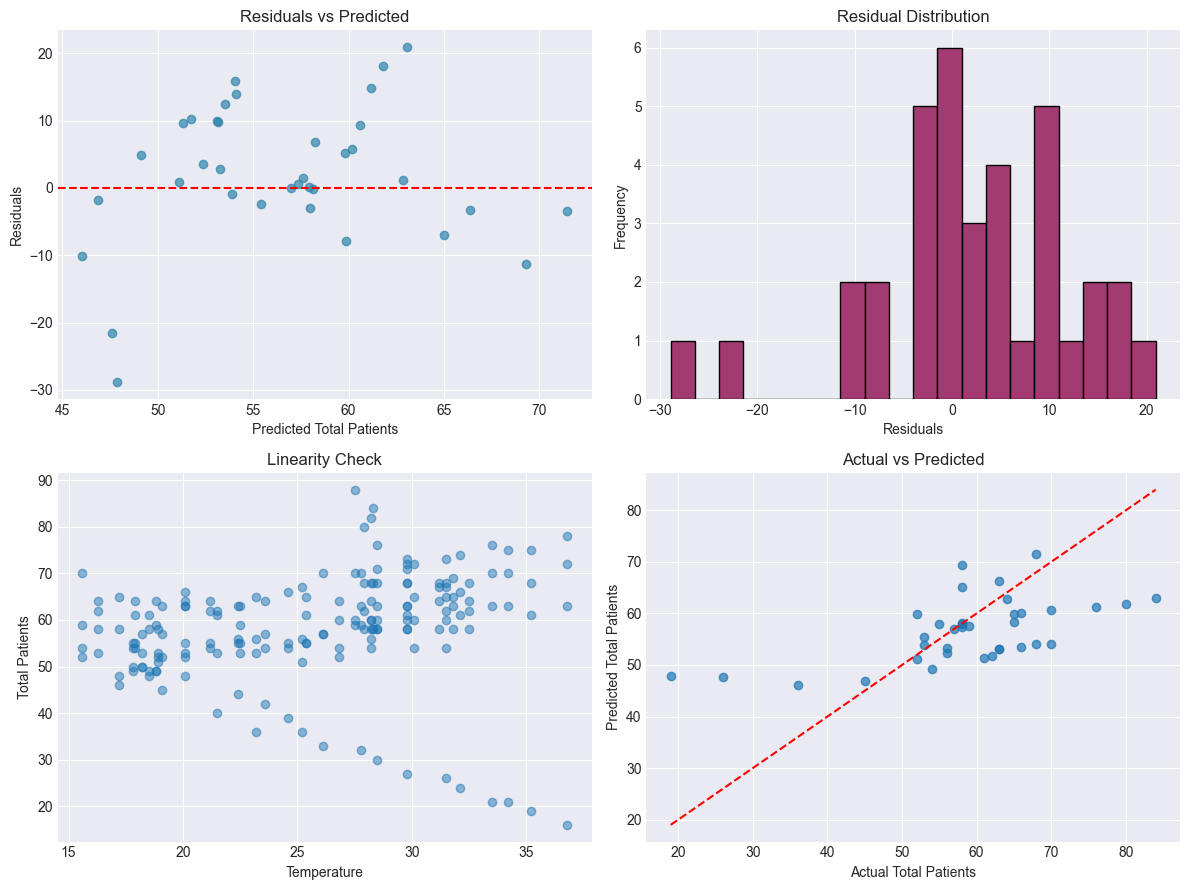

In [11]:
residuals = y_test - y_test_pred
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].scatter(y_test_pred, residuals, color='#2E86AB', alpha=0.7)
axes[0, 0].axhline(0, color='red', linestyle='--')
axes[0, 0].set_xlabel('Predicted Total Patients')
axes[0, 0].set_ylabel('Residuals')
axes[0, 0].set_title('Residuals vs Predicted')

axes[0, 1].hist(residuals, bins=20, color='#A23B72', edgecolor='black')
axes[0, 1].set_xlabel('Residuals')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Residual Distribution')

axes[1, 0].scatter(df['Temperature'], df['Total_Patient_Count'], alpha=0.5)
axes[1, 0].set_xlabel('Temperature')
axes[1, 0].set_ylabel('Total Patients')
axes[1, 0].set_title('Linearity Check')

axes[1, 1].scatter(y_test, y_test_pred, alpha=0.7)
min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())
axes[1, 1].plot([min_val, max_val], [min_val, max_val], 'r--')
axes[1, 1].set_xlabel('Actual Total Patients')
axes[1, 1].set_ylabel('Predicted Total Patients')
axes[1, 1].set_title('Actual vs Predicted')

plt.tight_layout()
plt.savefig('model_diagnostics.png', dpi=300, bbox_inches='tight')
plt.show()